# PDF page kinds: where the cut-offs go

The PDF reader (`docs/dev/pdf.md`) measures each page and `classifyPage` names it `text`, `mixed`, `scanned`,
`ocr-scan` or `blank`. The kind decides what a model is given: the text layer alone (`text`), the text and the page's
image (`mixed`), the image instead of a text layer that cannot be trusted (`scanned`), or an OCR layer read as text
over a page that is a picture (`ocr-scan`). Every cut-off was a first value chosen against synthetic fixtures. This
notebook reads them against real documents.

The corpus is 83 public PDFs (`corpus.json`): pdf.js's test files at a pinned commit, arXiv papers, Internet Archive
scans (with and without OCR layers) and Common Crawl's 2021 PDF sample. Every page was measured by the extension's own
reader (`measure-corpus.mjs`). The pages near a cut-off, plus a few controls per document (`select-pages.mjs`), were
rendered by the extension and labelled through `ml.step` (`label-pages.mjs`) by a local vision model
(`qwen3.8-flash-next:vision`, 373 pages), and a 40-page calibration subset by Claude Opus 5.5, chosen from where the
local model and our kind disagreed. Neither model saw our measurements: only the render, the extracted text (cut at
800 characters) and the definitions in `label-pages.mjs`.

**The labels are not ground truth.** Where the two models disagree is reported, and a cut-off moves only where both
point the same way.

In [1]:
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wmlnb

HERE = wmlnb.ROOT / "notebooks" / "pdf"
DATA = HERE / "data"
QWEN, OPUS = "qwen3.8-flash-next:vision", "litellm.anthropic/claude-opus-5-5"
FILES = ["docs.jsonl", "pages.jsonl", "selection.jsonl", "selection-opus.jsonl",
         "labels-qwen3.8-flash-next-vision.jsonl", "labels-litellm.anthropic-claude-opus-5-5.jsonl", "cost.json"]
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

def jsonl(name):
    return [json.loads(l) for l in (DATA / name).read_text().splitlines() if l.strip()]

pd.DataFrame([{"file": f"data/{f}", "sha256": wmlnb.sha256_file(DATA / f)[:16],
               "rows": len(jsonl(f)) if f.endswith(".jsonl") else None} for f in FILES])

,file,sha256,rows
0,data/docs.jsonl,c0e1f83997947079,83.0
1,data/pages.jsonl,33dd6616b37a9a92,2411.0
2,data/selection.jsonl,123c058ce597a2ab,374.0
3,data/selection-opus.jsonl,c1fb89a630618a7b,40.0
4,data/labels-qwen3.8-flash-next-vision.jsonl,a8b09966040bff2a,374.0
5,data/labels-litellm.anthropic-claude-opus-5-5....,a28ee3876d0860bb,40.0
6,data/cost.json,99cd862381e325fe,NaN


## The cut-offs, read from the source

The constants are read from `pdf-classify.ts` and `pdf-measure.ts`, never copied, and `classify` below is
`classifyPage` in Python. The check after it runs the port over every measured page and requires the kind the
extension wrote, so a rule tried here is the extension's rule with one thing changed.

In [2]:
SRC = wmlnb.ROOT / "src" / "pdf"
def constants(path):
    return {k: float(v.replace("_", "")) for k, v in re.findall(r"export const ([A-Z_]+) = ([0-9._]+);", path.read_text())}
C = constants(SRC / "pdf-classify.ts")
FULL_PAGE_COVER = constants(SRC / "pdf-measure.ts")["FULL_PAGE_COVER"]

def classify(m, c=C, ocr_min_chars=None):
    """classifyPage (pdf-classify.ts) over one page's measurements. `ocr_min_chars`, when set, is the usable characters
    an OCR layer needs to make a page `ocr-scan`, in place of TEXT_MIN_CHARS."""
    junk = m["brokenChars"] >= c["BROKEN_MIN_CHARS"] and m["brokenRatio"] > c["BROKEN_MAX_RATIO"]
    clean = m["brokenRatio"] <= c["BROKEN_MAX_RATIO"]
    enough = m["usableChars"] >= c["TEXT_MIN_CHARS"] and clean
    ocr_enough = enough if ocr_min_chars is None else (m["usableChars"] >= ocr_min_chars and clean)
    if ocr_enough and m["fullPageImage"] and m["invisibleShare"] >= c["OCR_INVISIBLE_SHARE"]: return "ocr-scan"
    if enough: return "mixed" if m["imageCover"] >= c["MIXED_COVER"] else "text"
    if junk or m["imageCover"] >= c["SCANNED_COVER"]: return "scanned"
    if m["usableChars"] < c["BLANK_CHARS"] and m["imageCover"] < c["BLANK_COVER"]: return "blank"
    return "mixed" if m["imageCover"] >= c["MIXED_COVER"] else "text"

pages = pd.DataFrame(jsonl("pages.jsonl"))
pages["src"] = pages.id.str.split("-").str[0]
port = pages.apply(lambda r: classify(r), axis=1)
assert (port == pages.kind).all(), pages[port != pages.kind][["id", "n", "kind"]]
print(f"the port reproduces all {len(pages)} measured kinds")
pd.Series(C | {"FULL_PAGE_COVER": FULL_PAGE_COVER}).to_frame("value")

the port reproduces all 2411 measured kinds


,value
TEXT_MIN_CHARS,150.00
BROKEN_MAX_RATIO,0.30
BROKEN_MIN_CHARS,20.00
SCANNED_COVER,0.50
MIXED_COVER,0.15
BLANK_COVER,0.02
BLANK_CHARS,3.00
OCR_INVISIBLE_SHARE,0.90
FULL_PAGE_COVER,0.90


## The corpus

Every document was read: none refused, none truncated. The `ia` scans are what most real scans are, which is why
`scanned` and `ocr-scan` dominate the page count; the labelled set caps each document, so a 500-page book does not
drown out a 3-page form.

In [3]:
docs = pd.DataFrame(jsonl("docs.jsonl"))
docs["src"] = docs.id.str.split("-").str[0]
print(f"{len(docs)} documents, {docs.bytes.sum() / 1e6:.1f} MB, {len(pages)} pages;",
      f"refused: {docs.get('refused', pd.Series(dtype=str)).notna().sum()}, truncated: {docs.get('truncated', pd.Series(dtype=str)).notna().sum()}")
pd.crosstab(pages.src, pages.kind, margins=True)

83 documents, 161.5 MB, 2411 pages; refused: 0, truncated: 0


kind,blank,mixed,ocr-scan,scanned,text,All
src,,,,,,
arxiv,0,43,0,1,273,317
cc2021,0,26,0,7,102,135
ia,0,0,455,1018,7,1480
pdfjs,3,9,0,27,440,479
All,3,78,455,1053,822,2411


## The labels

One row per labelled page, our measurements beside each model's label. `trust` is the decision the kind exists for:
whether the text layer is read as the page's words. Ours trusts it for `text`, `mixed` and `ocr-scan`; a model trusts
it when it called the layer `match`, `partial` or `hidden`. `partial` counts as trusted: the excerpt was cut at 800
characters, so on a long page `partial` says nothing more than `match`.

In [4]:
def labels(name):
    rows = jsonl(name)
    bad = [r for r in rows if not r.get("label")]
    for r in bad: print(f"{name}: {r['id']} p{r['n']} has no label: {r.get('error') or 'unparsed reply'}")
    return pd.DataFrame([{"id": r["id"], "n": r["n"], "kind_m": r["label"].get("kind"), "layer_m": r["label"].get("textLayer"),
                          "conf_m": r["label"].get("confidence")} for r in rows if r.get("label")])

TRUSTED = ["match", "partial", "hidden"]
q = labels("labels-qwen3.8-flash-next-vision.jsonl").rename(columns={"kind_m": "q_kind", "layer_m": "q_layer", "conf_m": "q_conf"})
o = labels("labels-litellm.anthropic-claude-opus-5-5.jsonl").rename(columns={"kind_m": "o_kind", "layer_m": "o_layer", "conf_m": "o_conf"})
L = pages.merge(q, on=["id", "n"]).merge(o, on=["id", "n"], how="left")
L["ours_trust"] = L.kind.isin(["text", "mixed", "ocr-scan"])
L["q_trust"] = L.q_layer.isin(TRUSTED)
L["o_trust"] = np.where(L.o_layer.notna(), L.o_layer.isin(TRUSTED), np.nan)
print(f"{len(L)} pages labelled by qwen, {L.o_kind.notna().sum()} of them by Opus")
print("qwen's confidence:", L.q_conf.value_counts().to_dict(), " Opus's:", L.o_conf.value_counts().to_dict())

labels-qwen3.8-flash-next-vision.jsonl: cc2021-0000-0000428 p1 has no label: render: unreadable
373 pages labelled by qwen, 40 of them by Opus
qwen's confidence: {'high': 371, 'medium': 2}  Opus's: {'high': 32, 'medium': 8}


### Kind against kind

Our kind (rows) against each model's (columns). The local model calls most image-only scans of typed pages `text`:
it names what the page shows, with the text layer `none`. Opus calls every one of those it saw `scanned`. So the
local model's `kind` is not read as scan-or-not anywhere below; its `textLayer` is, and on that the two models agree
on 38 of 40 pages.

In [5]:
display(pd.crosstab(L.kind, L.q_kind).rename_axis(index="ours", columns="qwen"))
display(pd.crosstab(L.q_layer, L.kind).rename_axis(index="qwen's text layer", columns="ours"))
lo = L[L.o_kind.notna()]
display(pd.crosstab(lo.kind, lo.o_kind).rename_axis(index="ours", columns="Opus"))
display(pd.crosstab(lo.q_kind, lo.o_kind).rename_axis(index="qwen", columns="Opus"))
display(pd.crosstab(lo.q_trust, lo.o_trust.astype(bool)).rename_axis(index="qwen trusts", columns="Opus trusts"))

qwen,blank,figure,mixed,scanned,text
ours,,,,,
blank,1,2,0,0,0
mixed,0,11,36,0,0
ocr-scan,0,0,4,4,31
scanned,13,4,8,10,81
text,7,4,42,0,115


ours,blank,mixed,ocr-scan,scanned,text
qwen's text layer,,,,,
garbled,0,0,0,7,4
hidden,0,0,3,3,0
match,0,24,16,10,64
none,3,0,0,81,0
partial,0,23,20,15,100


Opus,blank,figure,mixed,scanned,text
ours,,,,,
blank,0,2,0,0,0
mixed,0,3,0,0,0
ocr-scan,0,0,0,6,0
scanned,2,0,2,9,1
text,2,3,4,0,6


Opus,blank,figure,mixed,scanned,text
qwen,,,,,
blank,4,0,0,3,2
figure,0,8,0,0,0
mixed,0,0,6,0,0
scanned,0,0,0,5,0
text,0,0,0,7,5


Opus trusts,False,True
qwen trusts,,
False,14,2
True,0,24


### Trust against trust

The decision that matters most: a trusted bad layer gives the model wrong words, a distrusted good one costs an image
instead of text. Ours agrees with the local model on the pages below; the disagreements are listed after.

In [6]:
def agree(a, b): return f"{(L[a] == L[b]).sum()}/{len(L)} ({(L[a] == L[b]).mean():.1%})"
print("ours vs qwen:", agree("ours_trust", "q_trust"))
print("ours vs Opus:", f"{(lo.ours_trust == lo.o_trust.astype(bool)).sum()}/{len(lo)}")
display(pd.crosstab(L.ours_trust, L.q_trust).rename_axis(index="ours trusts", columns="qwen trusts"))
COLS = ["id", "n", "kind", "usableChars", "imageCover", "largestImage", "fullPageImage", "invisibleShare", "brokenRatio", "q_kind", "q_layer", "o_layer"]
L[L.ours_trust != L.q_trust].sort_values(["ours_trust", "id", "n"])[COLS + ["ours_trust"]]

ours vs qwen: 341/373 (91.4%)
ours vs Opus: 36/40


qwen trusts,False,True
ours trusts,,
False,91,28
True,4,250


,id,n,kind,usableChars,imageCover,largestImage,fullPageImage,invisibleShare,brokenRatio,q_kind,q_layer,o_layer,ours_trust
159,ia-aps8647-0001-001-umich-edu,1,scanned,63,1.000000,1.000000,True,1.0,0.000000,mixed,partial,NaN,False
160,ia-aps8647-0001-001-umich-edu,2,scanned,124,1.000000,1.000000,True,1.0,0.000000,scanned,hidden,NaN,False
165,ia-cat31287673,1,scanned,98,1.000000,1.000000,True,1.0,0.000000,blank,match,NaN,False
168,ia-cat31287673,4,scanned,146,1.000000,1.000000,True,1.0,0.000000,mixed,match,NaN,False
187,ia-cu31924000900849,1,scanned,6,1.000000,1.000000,True,1.0,0.000000,figure,partial,NaN,False
188,ia-cu31924000900849,2,scanned,73,1.000000,1.000000,True,1.0,0.000000,scanned,partial,NaN,False
189,ia-cu31924000900849,3,scanned,78,1.000000,1.000000,True,1.0,0.000000,text,partial,NaN,False
195,ia-englishkikuyuvo00mcgrgoog,3,scanned,93,1.000000,1.000000,True,1.0,0.000000,mixed,partial,NaN,False
201,ia-englishkikuyuvo00mcgrgoog,199,scanned,142,1.000000,1.000000,True,1.0,0.000000,scanned,partial,NaN,False
202,ia-englishkikuyuvo00mcgrgoog,200,scanned,129,1.000000,1.000000,True,1.0,0.000000,scanned,hidden,NaN,False


Two groups make up the disagreements:

- **Short OCR pages.** A scan with an OCR layer (one full-page image, all of its text invisible) whose layer holds fewer
  than `TEXT_MIN_CHARS` usable characters fails `enough` and falls to `scanned`: a title page, a chapter opening, a
  plate with a caption. The models read those layers as the page's words, but `scanned` is not a verdict that the
  layer is wrong: it sends the page's image, which on a short page is most of what it carries. The next section asks
  whether those pages should be `ocr-scan` instead.
- **Broken text layers.** `pdfjs-tamreview` (broken ratio 0.66 to 0.87, read by the local model as `partial`: some
  readable words among the junk) is distrusted by us, and two pages with ratios of 0.16 and 0.23 are trusted by us but
  `garbled` to the model (Opus confirms the 0.16 one). Too few pages either side of 0.3 to move `BROKEN_MAX_RATIO`.

## The OCR rule: should a short OCR layer make an `ocr-scan`?

An `ocr-scan` page is given to the model as its text alone; the image goes too only when the layer reads as broken
(`docs/spec/FILE_ATTACHMENTS.md`, the table of page kinds). The rule tried: a page is `ocr-scan` when its layer has at
least `BLANK_CHARS` usable characters (the point below which we call a page empty), with the same clean-layer,
full-page-image and invisible-share tests. Everything else stays.

In [7]:
OCR_MIN = C["BLANK_CHARS"]
L["kind_ocr"] = L.apply(lambda r: classify(r, ocr_min_chars=OCR_MIN), axis=1)
L["trust_ocr"] = L.kind_ocr.isin(["text", "mixed", "ocr-scan"])
print("labelled pages that change kind:", (L.kind_ocr != L.kind).sum())
print("ours vs qwen, before:", agree("ours_trust", "q_trust"), " after:", agree("trust_ocr", "q_trust"))
lo = L[L.o_kind.notna()]
print("ours vs Opus, before:", f"{(lo.ours_trust == lo.o_trust.astype(bool)).sum()}/{len(lo)}",
      " after:", f"{(lo.trust_ocr == lo.o_trust.astype(bool)).sum()}/{len(lo)}")
moved = L[L.kind_ocr != L.kind]
display(moved[["id", "n", "usableChars", "kind", "kind_ocr", "q_kind", "q_layer", "o_kind", "o_layer"]])
print("of the pages that move, qwen sees a picture (mixed or figure) on", moved.q_kind.isin(["mixed", "figure"]).sum())
allk = pages.apply(lambda r: classify(r, ocr_min_chars=OCR_MIN), axis=1)
print(f"over the whole corpus, {(allk != pages.kind).sum()} of {len(pages)} pages move:")
pd.crosstab(pages.kind, allk).rename_axis(index="now", columns="with the rule")

labelled pages that change kind: 23
ours vs qwen, before: 341/373 (91.4%)  after: 362/373 (97.1%)
ours vs Opus, before: 36/40  after: 36/40


,id,n,usableChars,kind,kind_ocr,q_kind,q_layer,o_kind,o_layer
159,ia-aps8647-0001-001-umich-edu,1,63,scanned,ocr-scan,mixed,partial,NaN,NaN
160,ia-aps8647-0001-001-umich-edu,2,124,scanned,ocr-scan,scanned,hidden,NaN,NaN
165,ia-cat31287673,1,98,scanned,ocr-scan,blank,match,NaN,NaN
168,ia-cat31287673,4,146,scanned,ocr-scan,mixed,match,NaN,NaN
187,ia-cu31924000900849,1,6,scanned,ocr-scan,figure,partial,NaN,NaN
188,ia-cu31924000900849,2,73,scanned,ocr-scan,scanned,partial,NaN,NaN
189,ia-cu31924000900849,3,78,scanned,ocr-scan,text,partial,NaN,NaN
192,ia-cu31924000900849,8,7,scanned,ocr-scan,blank,garbled,scanned,garbled
195,ia-englishkikuyuvo00mcgrgoog,3,93,scanned,ocr-scan,mixed,partial,NaN,NaN
201,ia-englishkikuyuvo00mcgrgoog,199,142,scanned,ocr-scan,scanned,partial,NaN,NaN


of the pages that move, qwen sees a picture (mixed or figure) on 5
over the whole corpus, 34 of 2411 pages move:


with the rule,blank,mixed,ocr-scan,scanned,text
now,,,,,
blank,3,0,0,0,0
mixed,0,78,0,0,0
ocr-scan,0,0,455,0,0
scanned,0,0,34,1019,0
text,0,0,0,0,822


The pages that move are short OCR pages only, all from `scanned` to `ocr-scan`, and the rule buys the local model's
agreement on trust while Opus's does not move: it gains one page and loses another, a 7-character layer that both
models call `garbled`. Trust is the wrong yardstick here, because the move also takes the image away, and on a fifth
of these pages the local model sees a picture (an illustrated title page, a plate); others are a handful of OCR'd
characters over a page whose content is its image. **The OCR rule stays.** What a short clean layer could still do is
travel WITH the image of a `scanned` page, a hundred characters beside three thousand image tokens; that is the
reader's choice of what to send, not the classifier's.

## `MIXED_COVER`: when a text page also needs its picture

For pages with enough text, the local model's `mixed` or `figure` reads as "the picture matters". The table sweeps the
cut: at each value, how many pages ours would call `mixed` that the model calls `text` (an image sent for nothing), and
how many the model sees a picture on that ours would call `text` (a picture lost).

,image for nothing,picture lost,"lost, no image at all",agree
cut,,,,
0.01,32,15,13,75.1%
0.02,29,17,13,75.7%
0.03,18,20,13,79.9%
0.05,5,25,13,84.1%
0.07,1,30,13,83.6%
0.09,0,33,13,82.5%
0.10,0,33,13,82.5%
0.12,0,37,13,80.4%
0.15,0,45,13,76.2%


highest image cover on a page qwen calls text: 0.086
Opus on the same pages (n = 12 ):


Opus: picture,False,True
qwen: picture,,
False,4,0
True,0,8


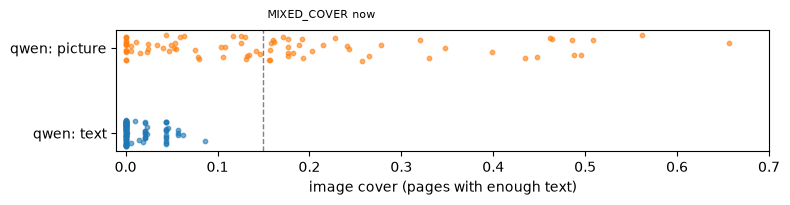

In [8]:
e = L[(L.usableChars >= C["TEXT_MIN_CHARS"]) & (L.brokenRatio <= C["BROKEN_MAX_RATIO"]) & ~L.kind.isin(["ocr-scan"])].copy()
e["q_pic"] = e.q_kind.isin(["mixed", "figure", "scanned"])
e["o_pic"] = np.where(e.o_kind.notna(), e.o_kind.isin(["mixed", "figure", "scanned"]), np.nan)
rows = []
for cut in [0.01, 0.02, 0.03, 0.05, 0.07, 0.09, 0.1, 0.12, 0.15, 0.2, 0.25]:
    pic = e.imageCover >= cut
    rows.append({"cut": cut, "image for nothing": int((pic & ~e.q_pic).sum()), "picture lost": int((~pic & e.q_pic).sum()),
                 "lost, no image at all": int((~pic & e.q_pic & (e.imageCover == 0)).sum()), "agree": f"{(pic == e.q_pic).mean():.1%}"})
display(pd.DataFrame(rows).set_index("cut"))
print("highest image cover on a page qwen calls text:", round(e[~e.q_pic].imageCover.max(), 3))
print("Opus on the same pages (n =", e.o_kind.notna().sum(), "):")
display(pd.crosstab(e[e.o_kind.notna()].q_pic, e[e.o_kind.notna()].o_pic.astype(bool)).rename_axis(index="qwen: picture", columns="Opus: picture"))

fig, ax = plt.subplots(figsize=(8, 2.2))
for y, (lab, s) in enumerate([("qwen: text", e[~e.q_pic]), ("qwen: picture", e[e.q_pic])]):
    ax.scatter(s.imageCover, np.full(len(s), y) + np.random.default_rng(0).uniform(-0.15, 0.15, len(s)), s=10, alpha=0.6)
ax.axvline(C["MIXED_COVER"], color="grey", ls="--", lw=1); ax.text(C["MIXED_COVER"], 1.35, " MIXED_COVER now", fontsize=8)
ax.set_yticks([0, 1], ["qwen: text", "qwen: picture"]); ax.set_xlabel("image cover (pages with enough text)"); ax.set_xlim(-0.01, 0.7)
plt.tight_layout(); plt.show()

No page the model calls `text` has more than about 9% of its area under images, and between that and the present 15%
every page is one the model sees a picture on. The cut moves down to just above the highest text page. What the
image cover cannot reach is the column "no image at all": vector figures (charts, plots and diagrams drawn as paths)
cover nothing by this measure. Both models call them `mixed` or `figure`; that needs a path-cover measure in
`pdf-measure.ts`, not a threshold.

## `SCANNED_COVER`: a page with little text that is a picture

For pages without enough text, the cover bands against what the models saw. "scan" is the local model's `scanned`, or
its `text` with no text layer (a picture of typed words).

In [9]:
f = L[L.usableChars < C["TEXT_MIN_CHARS"]].copy()
f["q_scan"] = (f.q_kind == "scanned") | ((f.q_kind == "text") & f.q_layer.isin(["none", "hidden"]))
bands = pd.cut(f.imageCover, [-0.001, 0.005, 0.02, 0.06, 0.3, 0.5, 0.7, 0.9, 1.0])
display(pd.crosstab(bands, f.q_kind).assign(scan=pd.crosstab(bands, f.q_scan).get(True, 0)))

q_kind,blank,figure,mixed,scanned,text,scan
imageCover,,,,,,
"(-0.001, 0.005]",8,3,0,0,8,0
"(0.06, 0.3]",0,0,2,0,0,0
"(0.3, 0.5]",0,8,1,0,0,0
"(0.5, 0.7]",1,1,1,1,10,11
"(0.7, 0.9]",4,0,0,0,44,44
"(0.9, 1.0]",8,3,5,9,18,19


Below 0.5 the model sees figures (scans of a figure are rare, plots on a mostly blank page common); from 0.5 up it
sees scans. The present cut sits where the data turns, and stays.

## `FULL_PAGE_COVER`: the Google scans

Some Google-digitised books on the Internet Archive put each page in an image that covers 60% to 90% of the page,
below `FULL_PAGE_COVER` (0.9). Whether that matters depends on whether any such page carries an OCR layer, since
`fullPageImage` is read only by the OCR test.

In [10]:
inv = pages[(pages.invisibleShare >= C["OCR_INVISIBLE_SHARE"]) & (pages.usableChars >= C["BLANK_CHARS"])]
print(f"{len(inv)} pages carry an invisible text layer; their largest image covers:")
display(inv.largestImage.describe().to_frame().T)
g = pages[(pages.largestImage >= 0.6) & (pages.largestImage < FULL_PAGE_COVER)]
print(f"{len(g)} pages in {g.id.nunique()} documents have a largest image between 0.6 and FULL_PAGE_COVER;",
      f"with any invisible text: {(g.invisibleGlyphs > 0).sum()}; usable characters, max: {g.usableChars.max()}")
g.groupby("id").agg(pages=("n", "size"), largest=("largestImage", "median"), usable_max=("usableChars", "max"), kinds=("kind", lambda k: dict(k.value_counts())))

489 pages carry an invisible text layer; their largest image covers:


,count,mean,std,min,25%,50%,75%,max
largestImage,489.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0


744 pages in 6 documents have a largest image between 0.6 and FULL_PAGE_COVER; with any invisible text: 0; usable characters, max: 1585


,pages,largest,usable_max,kinds
id,,,,
cc2021-0317-0317860,1,0.609741,1585,{'mixed': 1}
ia-cornwallparishr01rowegoog,179,0.751465,0,{'scanned': 179}
ia-kybalionastudyh00unkngoog,236,0.627625,0,{'scanned': 236}
ia-medeaeuripides00murrgoog,119,0.800049,0,{'scanned': 119}
ia-songskappakappa00gammgoog,140,0.755371,0,{'scanned': 140}
ia-yellowwallpaper00gilmgoog,69,0.849609,0,{'scanned': 69}


Every page with an OCR layer here has one image over the whole of it, and the pages whose largest image falls short
of the cut carry no invisible text, so they are `scanned` whatever `FULL_PAGE_COVER` is. The corpus has no page that would tell 0.9 from 0.6; it
stays until one turns up.

## `BLANK_*`: what counts as empty

Pages with fewer than 10 usable characters, against both models.

In [11]:
b = L[L.usableChars < 10][["id", "n", "kind", "usableChars", "imageCover", "q_kind", "q_layer", "o_kind"]]
display(b[b.imageCover < C["SCANNED_COVER"]].sort_values("usableChars"))

,id,n,kind,usableChars,imageCover,q_kind,q_layer,o_kind
295,pdfjs-22060-a1-01-plans,1,blank,0,0.0,figure,none,figure
322,pdfjs-issue19517,1,blank,0,0.0,blank,none,NaN
349,pdfjs-personwithdog,1,blank,0,0.0,figure,none,figure
325,pdfjs-issue5994,1,text,3,0.0,text,garbled,NaN
334,pdfjs-issue8795-reduced,1,text,3,0.0,blank,match,text
330,pdfjs-issue6961,1,text,5,0.0,blank,match,NaN
331,pdfjs-issue6961,2,text,5,0.0,blank,match,NaN
312,pdfjs-freeculture,186,text,7,0.0,blank,match,blank
304,pdfjs-freeculture,30,text,8,0.0,blank,match,blank
335,pdfjs-issue9262-reduced,1,text,8,0.0,blank,match,text


The models call a page with only a page number (5 to 9 characters) `blank`; ours calls it `text`, which sends those
characters and nothing else. The two cost the same, and the models split on them (Opus calls 2 `blank` and 2 `text`),
so `BLANK_CHARS` stays. The pages ours calls `blank` that both models call `figure` are vector drawings again: the path
measure, not the threshold.

## What the labels cost

Opus is priced by the bench's pricer at the price snapshot each call ran under; the local model's draw is read from
the box's event log over the run, as the bench does (`tests/e2e/bench/electricity.mjs`), and "above rest" is what the
run added to what the box draws idle.

In [12]:
cost = json.loads((DATA / "cost.json").read_text())
rows = []
for model, m in cost.items():
    en = m.get("energy") or {}
    rows.append({"model": model, "pages": m["calls"], "tokens in": m["promptTokens"], "tokens out": m["completionTokens"],
                 "s per page": round(m["wallMs"] / m["calls"] / 1000, 2),
                 "USD": round(m["usd"]["computed"], 3) if not m["local"] else None,
                 "Wh": round(en.get("Wh", np.nan), 1), "Wh above rest": round(en.get("aboveWh", np.nan), 1),
                 "electricity": f"{en['costAbove']:.4f} {en['currency']} above rest" if en else None,
                 "per page": f"${m['usd']['computed'] / m['calls']:.4f}" if not m["local"] else f"{en['aboveWh'] / m['calls']:.2f} Wh"})
pd.DataFrame(rows).set_index("model")

,pages,tokens in,tokens out,s per page,USD,Wh,Wh above rest,electricity,per page
model,,,,,,,,,
litellm.anthropic/claude-opus-5-5,40,120911,2692,2.98,0.658,NaN,NaN,NaN,$0.0165
qwen3.8-flash-next:vision,373,863554,14841,2.06,NaN,137.7,100.2,0.0265 EUR above rest,0.27 Wh


The local model labelled 373 pages for 2.6 euro cents of electricity above rest (0.27 Wh a page); Opus cost $0.016 a
page, over 200 times as much, and was needed only to say which of the local model's calls to believe. Whether anything
else ran on the box during the run was not checked, so the energy is the box's draw, not the model's alone.

## Decision (2026-10-28)

- **`MIXED_COVER` goes from 0.15 to 0.1**, just above the highest cover of any page the local model calls `text`.
- **Kept**: the OCR rule, `SCANNED_COVER`, `BLANK_*`, `BROKEN_MAX_RATIO`, `FULL_PAGE_COVER`, `TEXT_MIN_CHARS`, each
  for the reason in its section.
- **For the reader, not the classifier**: a `scanned` page whose OCR layer is short and clean could send that text
  beside its image.
- **Not a threshold**: vector figures. Both models see a picture where the image cover is 0; a path-cover measure in
  `pdf-measure.ts` is the next change, after which this notebook is run again over a re-measured corpus.